# Exploração inicial — estação Vitória (A612), 2021–2025

**Objetivo:**
Explorar os dados dos cinco últimos anos completos da estação A612 de Vitória, para entender o formato dos arquivos e avaliar a qualidade (completude) dos dados antes das análises de chuva. 

**Dados:**
Arquivos .CSV extraídos de ZIPs baixados do portal do INMET https://portal.inmet.gov.br/dadoshistoricos

**Como reproduzir:**
- Baixar os ZIPs anuais de 2021 a 2025;
- Extrair os CSVs da estação A612 em data/raw/inmet/
- A pasta data/raw/ não é versionada (ver .gitignore)

## 1. Configuração

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = Path('../data/raw/inmet')
STATION = 'A612'
RAIN = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
MIN_COMPLETENESS = 0.75   # Abaixo disso, o mês é excluído
LOW_CONFIDENCE = 0.90     # Entre 0,75 e 0,90: baixa confiança

files = sorted(DATA_DIR.glob(f'*{STATION}*'))
files

[WindowsPath('../data/raw/inmet/INMET_SE_ES_A612_VITORIA_01-01-2021_A_31-12-2021.CSV'),
 WindowsPath('../data/raw/inmet/INMET_SE_ES_A612_VITORIA_01-01-2022_A_31-12-2022.CSV'),
 WindowsPath('../data/raw/inmet/INMET_SE_ES_A612_VITORIA_01-01-2023_A_31-12-2023.CSV'),
 WindowsPath('../data/raw/inmet/INMET_SE_ES_A612_VITORIA_01-01-2024_A_31-12-2024.CSV'),
 WindowsPath('../data/raw/inmet/INMET_SE_ES_A612_VITORIA_01-01-2025_A_31-12-2025.CSV')]

## 2. Entendendo o arquivo do INMET

Antes de ler os cinco anos, examinamos um único arquivo (2021) para entender sua estrutura: as linhas de metadados, o separador, a codificação e as colunas.

In [3]:
with open(files[0], encoding='latin-1') as f:
    for _ in range(12):
        print(f.readline().rstrip())

REGIAO:;SE
UF:;ES
ESTACAO:;VITORIA
CODIGO (WMO):;A612
LATITUDE:;-20,27083332
LONGITUDE:;-40,30583333
ALTITUDE:;9
DATA DE FUNDACAO:;31/10/06
Data;Hora UTC;PRECIPITAÇÃO TOTAL, HORÁRIO (mm);PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB);PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB);PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB);RADIACAO GLOBAL (Kj/m²);TEMPERATURA DO AR - BULBO SECO, HORARIA (°C);TEMPERATURA DO PONTO DE ORVALHO (°C);TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C);TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C);UMIDADE REL. MAX. NA HORA ANT. (AUT) (%);UMIDADE REL. MIN. NA HORA ANT. (AUT) (%);UMIDADE RELATIVA DO AR, HORARIA (%);VENTO, DIREÇÃO HORARIA (gr) (° (gr));VENTO, RAJADA MAXIMA (m/s);VENTO, VELOCIDADE HORARIA (m/s);
2021/01/01;0000 UTC;0;1014,8;1014,8;1014,3;;25,5;19,7;25,5;25,1;19,7;19,4;71;69;70;12;7,8;2,5;
2021/01/01;0100 UTC;0;1014,9;1015,1;1014,8;;24,9;20;25,5;24,9;

In [4]:
df_2021 = pd.read_csv(files[0], encoding='latin-1', skiprows=8, decimal=',', sep=';')

In [5]:
df_2021.shape

(8760, 20)

In [6]:
df_2021.head()

,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)",Unnamed: 19
0,2021/01/01,0000 UTC,0.0,1014.8,1014.8,1014.3,NaN,25.5,19.7,25.5,25.1,19.7,19.4,71.0,69.0,70.0,12.0,7.8,2.5,NaN
1,2021/01/01,0100 UTC,0.0,1014.9,1015.1,1014.8,NaN,24.9,20.0,25.5,24.9,20.1,19.4,74.0,70.0,74.0,352.0,6.4,2.2,NaN
2,2021/01/01,0200 UTC,0.0,1014.4,1015.0,1014.4,NaN,24.7,19.9,25.0,24.7,20.0,19.8,75.0,73.0,74.0,354.0,6.7,1.9,NaN
3,2021/01/01,0300 UTC,0.0,1013.6,1014.4,1013.6,NaN,24.6,19.4,25.0,24.6,20.0,19.4,75.0,73.0,73.0,352.0,7.8,2.1,NaN
4,2021/01/01,0400 UTC,0.0,1013.1,1013.6,1013.1,NaN,22.9,18.7,24.7,22.9,19.4,18.5,77.0,70.0,77.0,332.0,7.2,1.1,NaN


In [7]:
df_2021.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 20 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Data                                                   8760 non-null   str    
 1   Hora UTC                                               8760 non-null   str    
 2   PRECIPITAÇÃO TOTAL, HORÁRIO (mm)                       7678 non-null   float64
 3   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)  7678 non-null   float64
 4   PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)        7677 non-null   float64
 5   PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)       7677 non-null   float64
 6   RADIACAO GLOBAL (Kj/m²)                                4099 non-null   float64
 7   TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)           7678 non-null   float64
 8   TEMPERATURA DO PONTO DE ORVALHO (°C)                   7678

In [8]:
# Descartando a coluna vazia

df_2021 = df_2021.drop(columns=['Unnamed: 19'])

In [9]:
df_2021.shape

(8760, 19)

In [10]:
df_2021[RAIN].describe()

count    7678.000000
mean        0.185361
std         1.255399
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        32.800000
Name: PRECIPITAÇÃO TOTAL, HORÁRIO (mm), dtype: float64

## 3. Leitura dos cinco anos

A função abaixo reúne o que aprendemos na seção 2: pula as 8 linhas de metadados, lê com separador `;`, vírgula decimal e codificação latin-1, descarta a coluna vazia e converte a data.

In [11]:
def read_inmet(path):
    """Lê um CSV de estação do INMET (dados horários)"""
    df = pd.read_csv(path, encoding='latin-1', skiprows=8, decimal=',', sep=';')
    df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
    df['Data'] = pd.to_datetime(df['Data'], format='%Y/%m/%d')
    return df

In [12]:
df_all = pd.concat([read_inmet(f) for f in files], ignore_index=True)
df_all.shape

(43824, 19)

## 4. Completude dos dados

In [13]:
by_year_month = df_all.groupby([df_all['Data'].dt.year, df_all['Data'].dt.month])[RAIN]
completeness = by_year_month.count() / by_year_month.size()   # valores exatos: esta série decide

excluded = completeness[completeness < MIN_COMPLETENESS]
low_confidence = completeness[(completeness >= MIN_COMPLETENESS) & (completeness < LOW_CONFIDENCE)]
len(excluded), len(low_confidence)

(9, 4)

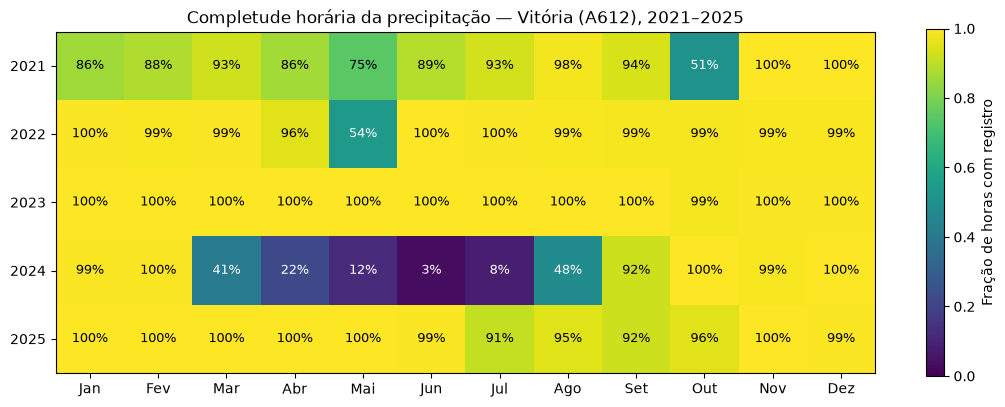

In [14]:
grid = completeness.unstack()   # anos nas linhas, meses nas colunas
months = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
          'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(grid, cmap='viridis', vmin=0, vmax=1)

ax.set_xticks(range(12), months)
ax.set_yticks(range(len(grid)), grid.index)

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        value = grid.iloc[i, j]
        color = 'white' if value < 0.6 else 'black'
        ax.text(j, i, f'{value:.0%}', ha='center', va='center', fontsize=9, color=color)

ax.set_title('Completude horária da precipitação — Vitória (A612), 2021–2025')
fig.colorbar(im, ax=ax, label='Fração de horas com registro')
plt.tight_layout()
plt.show()

### Achados

A completude horária da precipitação (fração de horas com registro em cada mês) na estação de Vitória (A612), de 2021 a 2025, mostra falhas relevantes:

- **2021:** falhas espalhadas ao longo do ano; outubro com apenas 51% das horas registradas.
- **2022:** quase completo, exceto maio (54%).
- **2023:** praticamente completo.
- **2024:** a estação ficou praticamente inoperante de março a agosto (completude entre 3% e 48%).
- **2025:** quase completo, com pequenas falhas no segundo semestre.

Somar a chuva de meses incompletos subestima o total, porque um mês sem dados pareceria um mês seco. Por isso, a completude é verificada antes de qualquer cálculo.

### Critério adotado

- **Meses com completude ≥ 75%** entram na análise.
- **Meses entre 75% e 90%** entram, mas são **sinalizados como de baixa confiança**: podem ter até ~7 dias sem registro, e o total pode estar subestimado.
- **Meses abaixo de 75%** são excluídos.
- O critério é aplicado aos valores exatos, sem arredondamento (ex.: maio de 2021 tem 74,6% e é excluído).

**Justificativa:** um critério mais rígido (≥ 90%) seria tecnicamente preferível para precipitação, mas excluiria muitos meses num recorte de apenas cinco anos. O critério de 75% com sinalização preserva os dados e torna a incerteza visível.

**Resultado:** 51 dos 60 meses entram na análise; 9 são excluídos (mai e out/2021, mai/2022, mar a ago/2024) e 4 são de baixa confiança (jan, fev, abr e jun/2021).

### Escopo

O recorte de cinco anos (2021–2025) serve para validar o processo de leitura e análise (MVP). A série completa da estação, desde 2006, será incorporada depois, o que dará médias mensais mais robustas.

## 5. Investigação das falhas

O mapa de calor mostra dois padrões que merecem investigação: a pane de março a agosto de 2024 e a baixa completude recorrente em maio (2021, 2022 e 2024). Antes de usar os dados, é preciso entender a natureza dessas falhas: a estação inteira parou de registrar, ou só o pluviômetro?

In [15]:
temp = [col for col in df_all.columns if 'BULBO SECO' in col][0]
temp

'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)'

In [16]:
def completeness_by_month(df, variables, years=None):
    """Fração de horas com registro, por ano e mês, para cada variável.

    df: DataFrame horário do INMET (saída de read_inmet).
    variables: dicionário {rótulo: nome da coluna}.
    years: lista de anos; se None, usa todo o período.
    """
    if years is not None:
        df = df[df['Data'].dt.year.isin(years)]
    grouped = df.groupby([df['Data'].dt.year, df['Data'].dt.month])
    table = pd.DataFrame({
        label: grouped[column].count() / grouped.size()
        for label, column in variables.items()
    })
    return table.rename_axis(['ano', 'mês'])

In [17]:
variables = {'chuva': RAIN, 'temperatura': temp}


### 5.1 Pane de março a agosto de 2024

**Hipóteses:**
- H1: falha geral da estação (todas as variáveis ausentes juntas);
- H2: horas sem chuva registradas como vazio, em vez de 0,0.

**Teste:** comparar a completude mensal da precipitação com a da temperatura do ar (bulbo seco) em 2024.

In [18]:
completeness_by_month(df_all, variables, years=[2024]).round(2)

chuva  temperatura
ano  mês                    
2024 1     0.99         0.99
     2     1.00         1.00
     3     0.41         0.41
     4     0.22         0.22
     5     0.12         0.12
     6     0.03         0.03
     7     0.08         0.08
     8     0.48         0.48
     9     0.92         0.92
     10    1.00         1.00
     11    0.99         0.99
     12    1.00         1.00

**Resultado:** completude idêntica nas duas variáveis em todos os meses (ex.: jun/2024 = 3% em ambas).

**Conclusão:** H1 confirmada; H2 refutada. As horas continuam no arquivo, mas todas as medições vêm vazias: a estação deixou de registrar, não apenas o pluviômetro. A degradação gradual (mar–jul) e a recuperação em set sugerem uma falha intermitente até a manutenção. Os meses excluídos pelo critério de 75% continuam excluídos; não há como recuperar a chuva desse período a partir deste arquivo.

### 5.2 Baixa completude em maio

Dos três maios com baixa completude, 2022 é o caso mais claro: o de 2021 ficou no limite do critério (74,6%), e o de 2024 faz parte da pane de março a agosto, já tratada na 5.1.

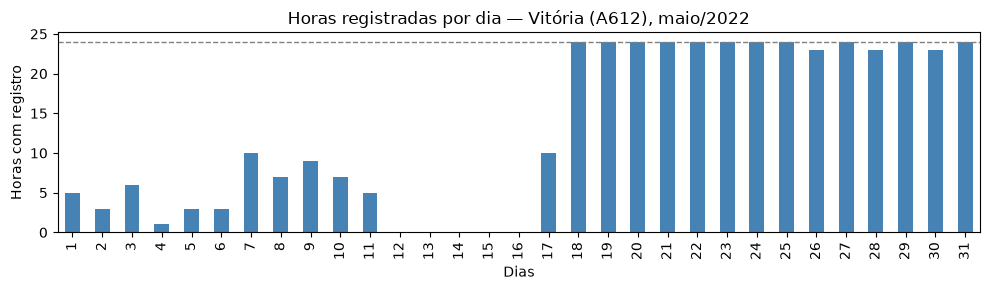

In [19]:
may_2022 = df_all[(df_all['Data'].dt.year == 2022) & (df_all['Data'].dt.month == 5)]
hours_per_day = may_2022.groupby(may_2022['Data'].dt.day)[RAIN].count()

ax = hours_per_day.plot(kind='bar', figsize=(10, 3), color='steelblue')
ax.axhline(24, color='gray', linestyle='--', linewidth=1)   # dia completo
ax.set_xlabel('Dias')
ax.set_ylabel('Horas com registro')
ax.set_title('Horas registradas por dia — Vitória (A612), maio/2022')
plt.tight_layout()
plt.show()

**Observação:** o mês tem quatro fases: funcionamento intermitente do dia 1 ao 11 (1 a 10 horas por dia), parada total do dia 12 ao 16, retomada parcial no dia 17 e registro completo a partir do dia 18.

**Hipóteses:**
- H1: a falha começou no fim de abril (abril teve 96% de completude);
- H2: a estação voltou a funcionar na tarde do dia 17 (o dia teve 10 horas de registro).

**Testes:**
- H1: listar os dias incompletos de abril de 2022;
- H2: listar as horas registradas no dia 17, convertendo de UTC para a hora local.

In [20]:
apr_2022 = df_all[(df_all['Data'].dt.year == 2022) & (df_all['Data'].dt.month == 4)]
hours_apr = apr_2022.groupby(apr_2022['Data'].dt.day)[RAIN].count()
hours_apr[hours_apr < 24]

Data
15    23
28    23
29    10
30     8
Name: PRECIPITAÇÃO TOTAL, HORÁRIO (mm), dtype: int64

In [21]:
day_17 = may_2022[may_2022['Data'].dt.day == 17]
day_17.dropna(subset=[RAIN])['Hora UTC']

12037    1300 UTC
12038    1400 UTC
12039    1500 UTC
12040    1600 UTC
12041    1700 UTC
12043    1900 UTC
12044    2000 UTC
12045    2100 UTC
12046    2200 UTC
12047    2300 UTC
Name: Hora UTC, dtype: str

**Resultado:**
- H1: em abril, os dias 15 e 28 perderam uma hora isolada cada (23 h), o que é normal em qualquer estação. A degradação começa no dia 29 (10 h de registro) e se agrava no dia 30 (8 h), continuando em maio.
- H2: o primeiro registro do dia 17 é às 13:00 UTC, ou seja, 10h no horário de Brasília (UTC−3). Dessa hora em diante, só falta uma hora isolada (18:00 UTC, 15h local).

**Conclusão:**
- H1 confirmada: a falha começou em 29 de abril de 2022.
- H2 refutada: a estação voltou a funcionar no fim da manhã do dia 17, não à tarde. A suposição vinha da contagem de horas, sem considerar quais horas eram nem o fuso UTC.
- O episódio de 2022 tem a mesma assinatura da pane de 2024: funcionamento intermitente, parada total e retorno abrupto, compatível com uma intervenção de manutenção. A diferença está na duração: cerca de três semanas em 2022 contra seis meses em 2024.

### 5.3 Abrangência das falhas: estação ou sensor?

**Hipóteses:**
- H1: falha geral da estação (todas as variáveis ausentes juntas);
- H2: horas sem chuva registradas como vazio, em vez de 0,0.

**Testes:**
- comparar a completude mensal da precipitação e da temperatura do ar (bulbo seco) em 2022;
- comparar, hora a hora, a ausência de registro das duas variáveis em todo o período (2021–2025).

In [22]:
completeness_by_month(df_all, variables, years=[2022]).round(2)

chuva  temperatura
ano  mês                    
2022 1     1.00         1.00
     2     0.99         0.99
     3     0.99         0.99
     4     0.96         0.96
     5     0.54         0.54
     6     1.00         1.00
     7     1.00         1.00
     8     0.99         0.99
     9     0.99         0.99
     10    0.99         0.99
     11    0.99         0.99
     12    0.99         0.99

In [23]:
same_gaps = df_all[RAIN].isna() == df_all[temp].isna()
same_gaps.mean()

np.float64(0.9999087258123402)

In [24]:
mismatch = df_all[~same_gaps]
len(mismatch), mismatch[['Data', 'Hora UTC', RAIN, temp]]

(4,
             Data  Hora UTC  PRECIPITAÇÃO TOTAL, HORÁRIO (mm)  \
 15732 2022-10-18  1200 UTC                               0.0   
 23966 2023-09-26  1400 UTC                               0.0   
 42661 2025-11-13  1300 UTC                               0.0   
 42662 2025-11-13  1400 UTC                               0.0   
 
        TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)  
 15732                                           NaN  
 23966                                           NaN  
 42661                                           NaN  
 42662                                           NaN  )

**Resultado:** a ausência de registro de chuva e de temperatura coincide em 43.820 das 43.824 horas (99,99%). As 4 horas discordantes têm a mesma direção: a chuva foi registrada (0,0 mm) e a temperatura ficou vazia (18/10/2022, 26/09/2023 e duas horas em 13/11/2025).

**Conclusão:**
- H1 confirmada para toda a série: quando falta registro de chuva, a estação inteira parou. O pluviômetro nunca falhou isoladamente; as raras falhas isoladas foram do sensor de temperatura.
- H2 refutada: horas sem chuva são registradas como 0,0, não como vazio. Se H2 fosse verdadeira, haveria horas com chuva vazia e temperatura presente, o que não ocorre.
- Implicação: os meses incompletos não podem ser preenchidos com zero, porque a ausência representa estação parada, não tempo seco. Isso sustenta o critério da seção 4: excluir os meses abaixo de 75% em vez de completá-los.
- Observação (não conclusiva): as 4 falhas isoladas ocorreram entre 9h e 11h no horário local, o que seria compatível com visitas de manutenção, mas quatro casos não permitem afirmar isso.

## 6. Conclusões e próximos passos

### Conclusões

- **Formato dos dados:** os CSVs do INMET têm 8 linhas de metadados antes do cabeçalho, separador `;`, vírgula decimal, codificação latin-1, horário em UTC e uma coluna vazia no fim; a função `read_inmet` trata tudo isso.
- **Qualidade:** com o critério de completude mínima de 75%, 51 dos 60 meses entram na análise; 9 são excluídos e 4 (entre 75% e 90%) ficam sinalizados como de baixa confiança.
- **Natureza das falhas:** toda ausência de registro de chuva corresponde a uma parada da estação inteira; o pluviômetro nunca falhou isoladamente. Por isso, os meses incompletos são excluídos, e não preenchidos com zero.
- **Episódios de falha:** 2022 e 2024 têm a mesma assinatura (funcionamento intermitente, parada total e retorno abrupto, compatível com manutenção), mas durações muito diferentes: cerca de três semanas (fim de abril a meados de maio de 2022) contra seis meses (março a agosto de 2024).

### Próximos passos

- carregar os dados num banco PostgreSQL (tabelas de estações e de medições horárias), como base para as análises em SQL e para o painel no Power BI;
- analisar a chuva em si, em SQL: totais mensais, ranking de meses e anos, estações do ano;
- converter os horários de UTC para a hora local antes de calcular totais diários;
- ampliar para a série completa (desde 2006) e testar se as falhas de maio se repetem.